In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import python_anesthesia_simulator as pas
from scripts.new_hemo_class import NewHemoModel

In [3]:
data_raw = pd.read_csv('data/database.csv')


In [4]:
data = data_raw.copy()
p_dist_bis = [
    -8.60412601e-11,
    1.53817088e-07,
    -9.35659716e-05, 
    1.14438483e-02,
    8.07370704e+00]
bis = []
dist_list = []
loss=0
for caseid, data_case in data.groupby('caseid'):
    time_intubation = data_case['intubation_time'].iloc[0]
    time = data_case['Time'].values - time_intubation
    dist = np.polyval(p_dist_bis, time)
    dist = dist.clip(0, 20)
    dist_list+=list(dist)
    bis_model = pas.BIS_model(hill_model='Bouillon', age=data_case['age'].iloc[0])
    e0_init = bis_model.E0
    bis_model.E0 = data_case['BIS'].iloc[0]
    bis_model.Emax *= bis_model.E0 / e0_init
    bis_case = bis_model.compute_bis(data_case['Ce_prop'].values, data_case['Ce_remi'].values)
    bis+=list(bis_case)
data = data.drop(columns=['BIS_sim'])
data.insert(0, "BIS_sim", bis)

data['TPR'] = (data['MAP'] / (data['HR'] * data['SV'])).clip(0, 0.04)
data['TPR_sim'] = (data['MAP_sim'] / (data['HR_sim'] * data['SV_sim'])).clip(0, 0.04)

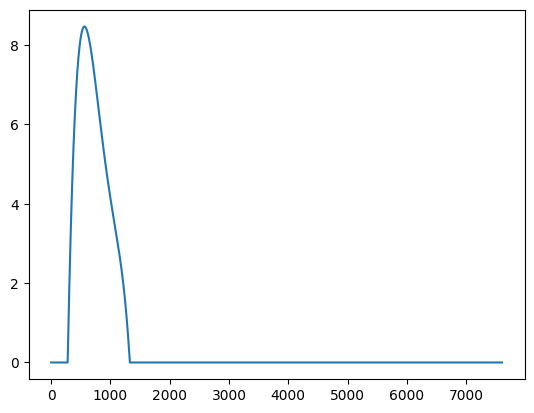

In [5]:
plt.plot(dist)

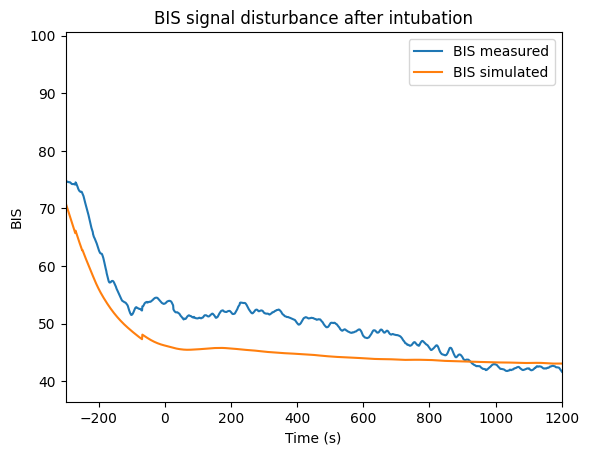

In [6]:
data['Time_aligned'] = data['Time'] - data['intubation_time']
data.groupby('Time_aligned').BIS.mean().plot(label='BIS measured')
data.groupby('Time_aligned').BIS_sim.mean().plot(label='BIS simulated')
plt.xlim(-5*60, 20*60)
plt.legend()
plt.xlabel('Time (s)')
plt.ylabel('BIS')
plt.title('BIS signal disturbance after intubation')
plt.show()

In [7]:
caseid = data.caseid.unique()[0]
# caseid = 2029
data_case = data.query('caseid == @caseid')
age = data_case.age.iloc[0]
height = data_case.height.iloc[0]
weight = data_case.weight.iloc[0]
sex = data_case.sex.iloc[0]
bis_base = data_case.bis_base.iloc[0]
hr_base = data_case.hr_base.iloc[0]
map_base = data_case.map_base.iloc[0]
sv_base = data_case.sv_base.iloc[0]


model = "Eleveld"  # Eleveld model
Patient_simu = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
    hr_base=hr_base,
    co_base=sv_base*hr_base/1000,  # L to ml
    map_base=map_base
)

Patient_simu_dist = pas.Patient(
    [age, height, weight, sex],
    model_propo=model,  # "Schnider",
    model_remi=model,  # "Minto",
    model_bis='Fuentes',
)

Patient_simu_dist.hemo_pd = NewHemoModel(
        age=Patient_simu_dist.age,
        ts=Patient_simu_dist.ts,
        random=False,
        hr_base=hr_base,
        sv_base=sv_base,  # L to ml
        map_base=map_base
    )
time_max = 30*60

# sv_vec = min
# gain = 1e-6
# min = [-gain, -gain, 0.1, -gain, 0.4, 0.1]
# max = [gain, gain, 10, gain, 5, 10]
# tpr_vec = min
dist_input = np.zeros(10000)
intubation_time = data_case.intubation_time.iloc[0]
opstart = data_case.opstart.iloc[0]
dist_input[intubation_time - int(2*60/1):intubation_time] = 1  # step disturbance after 5 seconds
surg_input = np.zeros(10000)
surg_input[opstart:] = 1


param = {'int_hr': 0.0849954176401289, 'emax_propo_tpr': 0.023733132184657085, 'fb': -0.3672899549950461,
         'tpr_k': 1.1256297341273485e-05, 'sv_k': 0.18035095427137257, 'hr_k': 8.677453095961003}

param_vec = [param[key] for key in param.keys()]

Patient_simu_dist.hemo_pd.int_hr = -param_vec[0]
Patient_simu_dist.hemo_pd.emax_propo_tpr = -param_vec[1]
Patient_simu_dist.hemo_pd.fb = param_vec[2]
Patient_simu_dist.hemo_pd.dist_intub_tpr_tau = 3
Patient_simu_dist.hemo_pd.dist_intub_tpr_k = param_vec[3]
Patient_simu_dist.hemo_pd.dist_intub_sv_tau = 2.7
Patient_simu_dist.hemo_pd.dist_intub_sv_k = param_vec[4]
Patient_simu_dist.hemo_pd.dist_intub_hr_tau = 40
Patient_simu_dist.hemo_pd.dist_intub_hr_k = param_vec[5]
Patient_simu_dist.hemo_pd.intub_input = dist_input

Patient_simu_dist.hemo_pd.dist_surg_tpr_tau = 5*60
Patient_simu_dist.hemo_pd.dist_surg_tpr_k = 0.001
Patient_simu_dist.hemo_pd.dist_surg_sv_tau = 3*60
Patient_simu_dist.hemo_pd.dist_surg_sv_k = 17
Patient_simu_dist.hemo_pd.dist_surg_hr_tau = 5*60
Patient_simu_dist.hemo_pd.dist_surg_hr_k = 10
Patient_simu_dist.hemo_pd.surg_input = surg_input

Patient_simu_dist.hemo_pd.disturbance_dynamic()


x_dist = np.zeros((len(data_case['Propofol']), 3))
data_case = data_case.query('Time <= @time_max')
for time in range(len(data_case['Propofol'])):
    Patient_simu.one_step(u_propo=data_case['Propofol'].iloc[time]*20/3600,
    u_remi=data_case['Remifentanil'].iloc[time]*20/3600, noise=False)
    Patient_simu_dist.one_step(u_propo=data_case['Propofol'].iloc[time]*20/3600,
    u_remi=data_case['Remifentanil'].iloc[time]*20/3600, noise=False)
    # x_dist[time,0] = Patient_simu_dist.hemo_pd.dist_tpr

df_simu = Patient_simu.dataframe
df_simu_dist = Patient_simu_dist.dataframe

# df_simu = Patient_simu.full_sim(
#     u_propo=data_case['Propofol']*20/3600,
#     u_remi=data_case['Remifentanil']*20/3600
#     )
# df_simu_dist = Patient_simu_dist.full_sim(
#     u_propo=data_case['Propofol']*20/3600,
#     u_remi=data_case['Remifentanil']*20/3600
#     )

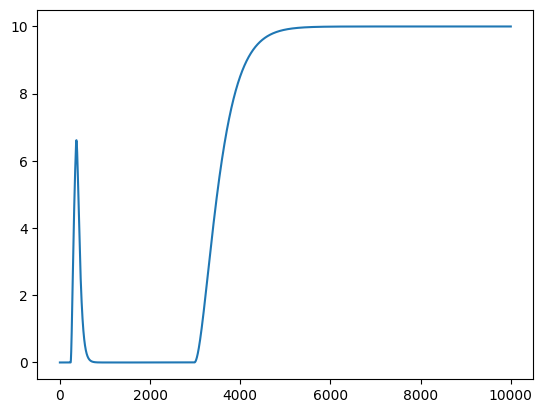

In [8]:
plt.plot(Patient_simu_dist.hemo_pd.dist_hr)

In [9]:
# for signal in ['HR', 'MAP', 'SV', 'TPR']:
#     plt.figure()
#     plt.plot(df_simu['Time']/60, df_simu[signal], label='no_dist')
#     plt.plot(df_simu_dist['Time']/60, df_simu_dist[signal], label='dist')
#     if signal in data_case.columns:
#         plt.plot(data_case['Time']/60, data_case[signal], label='data', alpha=0.5)
#     plt.xlabel('Time (min)')
#     plt.ylabel(f'{signal}')
#     plt.legend()
#     plt.show()

In [10]:
signal_list = ['BIS', 'MAP', 'HR', 'SV']
data_sim_dist = pd.read_csv('./data/simulation_new_param.csv')
data_sim_dist['MAP'] = data_sim_dist['HR']*data_sim_dist['SV']*data_sim_dist['TPR']
data_merged = pd.merge(data, data_sim_dist, on=['caseid', 'Time'], how='left', suffixes=('', '_dist'))
data_merged['BIS_dist'] = data_merged['BIS_sim'] + dist_list

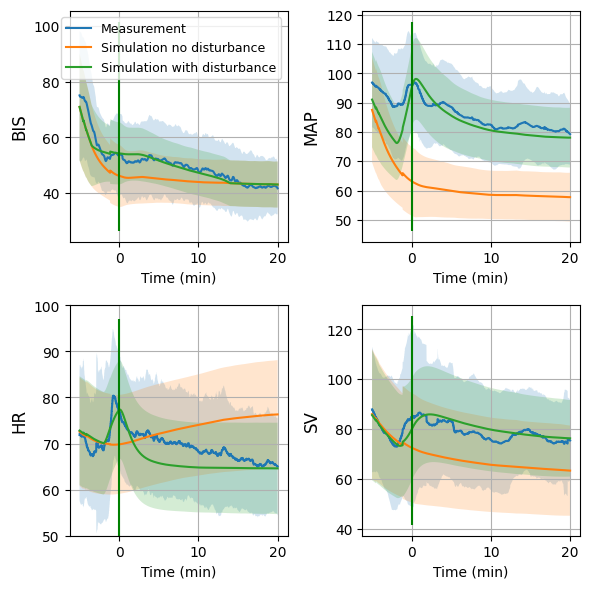

In [14]:

data_merged['Time_aligned'] = data_merged['Time'] - data_merged['intubation_time']
data_intub = data_merged.query("(Time_aligned>= -5*60) & (Time_aligned <=20*60)").copy()
plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    y_dist = data_intub.groupby("Time_aligned")[f"{signal}_dist"].mean().reset_index()
    y_dist_std = data_intub.groupby("Time_aligned")[f"{signal}_dist"].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measurement')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='Simulation no disturbance')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    plt.plot(x, y_dist[f"{signal}_dist"].values, label='Simulation with disturbance')
    plt.fill_between(x, y_dist[f"{signal}_dist"].values-y_dist_std[f"{signal}_dist"].values, y_dist[f"{signal}_dist"].values+y_dist_std[f"{signal}_dist"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
plt.tight_layout()
plt.savefig('output/dist_intub.pdf', dpi=300)
plt.show()

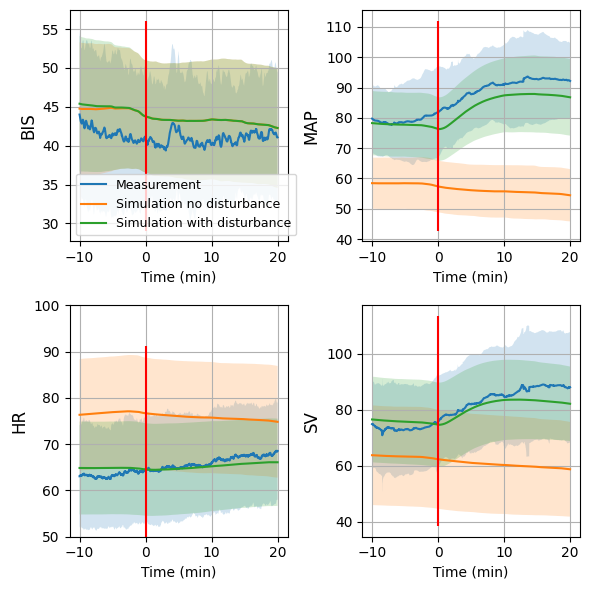

In [15]:

data_merged['Time_aligned'] = data_merged['Time'] - data_merged['opstart']
data_intub = data_merged.query("(Time_aligned>= -10*60) & (Time_aligned <=20*60)").copy()
plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    y_dist = data_intub.groupby("Time_aligned")[f"{signal}_dist"].mean().reset_index()
    y_dist_std = data_intub.groupby("Time_aligned")[f"{signal}_dist"].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measurement')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='Simulation no disturbance')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    plt.plot(x, y_dist[f"{signal}_dist"].values, label='Simulation with disturbance')
    plt.fill_between(x, y_dist[f"{signal}_dist"].values-y_dist_std[f"{signal}_dist"].values, y_dist[f"{signal}_dist"].values+y_dist_std[f"{signal}_dist"].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
# plt.suptitle("Aligned on end of intubation")
plt.tight_layout()
plt.savefig('output/dist_surgery.pdf', dpi=300)   
plt.show()

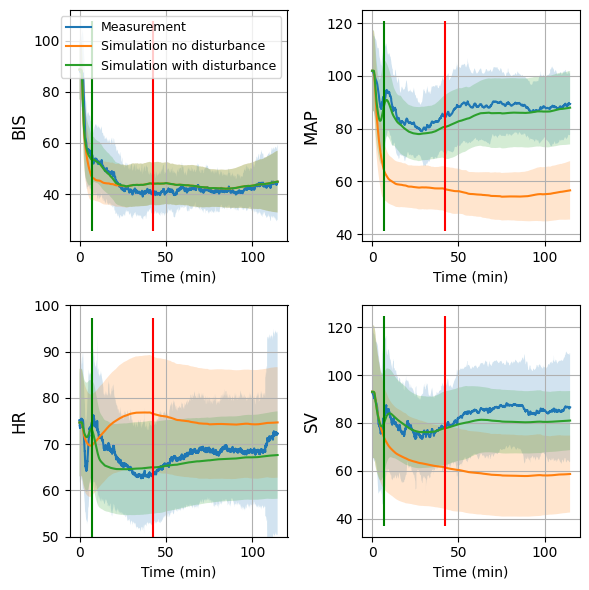

In [13]:

data_merged['Time_aligned'] = data_merged['Time']
min_case_duration = data.groupby('caseid')['Time'].max().min()
data_intub = data_merged.query('Time<@min_case_duration').copy()
intub_median = np.median(data_merged['intubation_time'].unique())
opstart_median = np.median(data_merged['opstart'].unique())
plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_intub.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_intub.groupby("Time_aligned")[signal].std().reset_index()
    y_sim = data_intub.groupby("Time_aligned")[f"{signal}_sim"].mean().reset_index()
    y_sim_std = data_intub.groupby("Time_aligned")[f"{signal}_sim"].std().reset_index()
    y_dist = data_intub.groupby("Time_aligned")[f"{signal}_dist"].mean().reset_index()
    y_dist_std = data_intub.groupby("Time_aligned")[f"{signal}_dist"].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measurement')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_sim[f"{signal}_sim"].values, label='Simulation no disturbance')
    plt.fill_between(x, y_sim[f"{signal}_sim"].values-y_sim_std[f"{signal}_sim"].values, y_sim[f"{signal}_sim"].values+y_sim_std[f"{signal}_sim"].values
    , alpha = 0.2)
    plt.plot(x, y_dist[f"{signal}_dist"].values, label='Simulation with disturbance')
    plt.fill_between(x, y_dist[f"{signal}_dist"].values-y_dist_std[f"{signal}_dist"].values, y_dist[f"{signal}_dist"].values+y_dist_std[f"{signal}_dist"].values
    , alpha = 0.2)
    ylim = plt.gca().get_ylim()
    plt.vlines(intub_median/60, ylim[0], ylim[1], 'g')
    plt.vlines(opstart_median/60, ylim[0], ylim[1], 'r')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    if signal=='HR':
        plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
plt.tight_layout()
plt.savefig('output/dist_all.pdf', dpi=300)   
plt.show()